             Model  Train R^2  Test R^2  Train RMSE  Test RMSE  Train MSE  Test MSE  Train MAE  Test MAE
 Gradient Boosting   0.995321  0.990028    1.789274   2.653856   3.201502  7.042953   1.506924  2.129182
     Random Forest   0.995315  0.985328    1.790429   3.219138   3.205636 10.362848   1.469946  2.551992
Polynomial (Deg 2)   0.984073  0.975425    3.301126   4.166218  10.897431 17.357376   2.604057  3.409403
               SVR   0.972391  0.970502    4.346281   4.564450  18.890161 20.834207   3.489998  3.894442
 Linear Regression   0.972892  0.969998    4.306630   4.603287  18.547064 21.190252   3.534161  3.861970
  Lasso Regression   0.972847  0.969585    4.310175   4.634909  18.577608 21.482386   3.555245  3.886958
  Ridge Regression   0.972654  0.968832    4.325463   4.691925  18.709629 22.014156   3.583028  3.933436
     Decision Tree   0.983934  0.938357    3.315410   6.598366  10.991945 43.538431   2.241927  4.479118


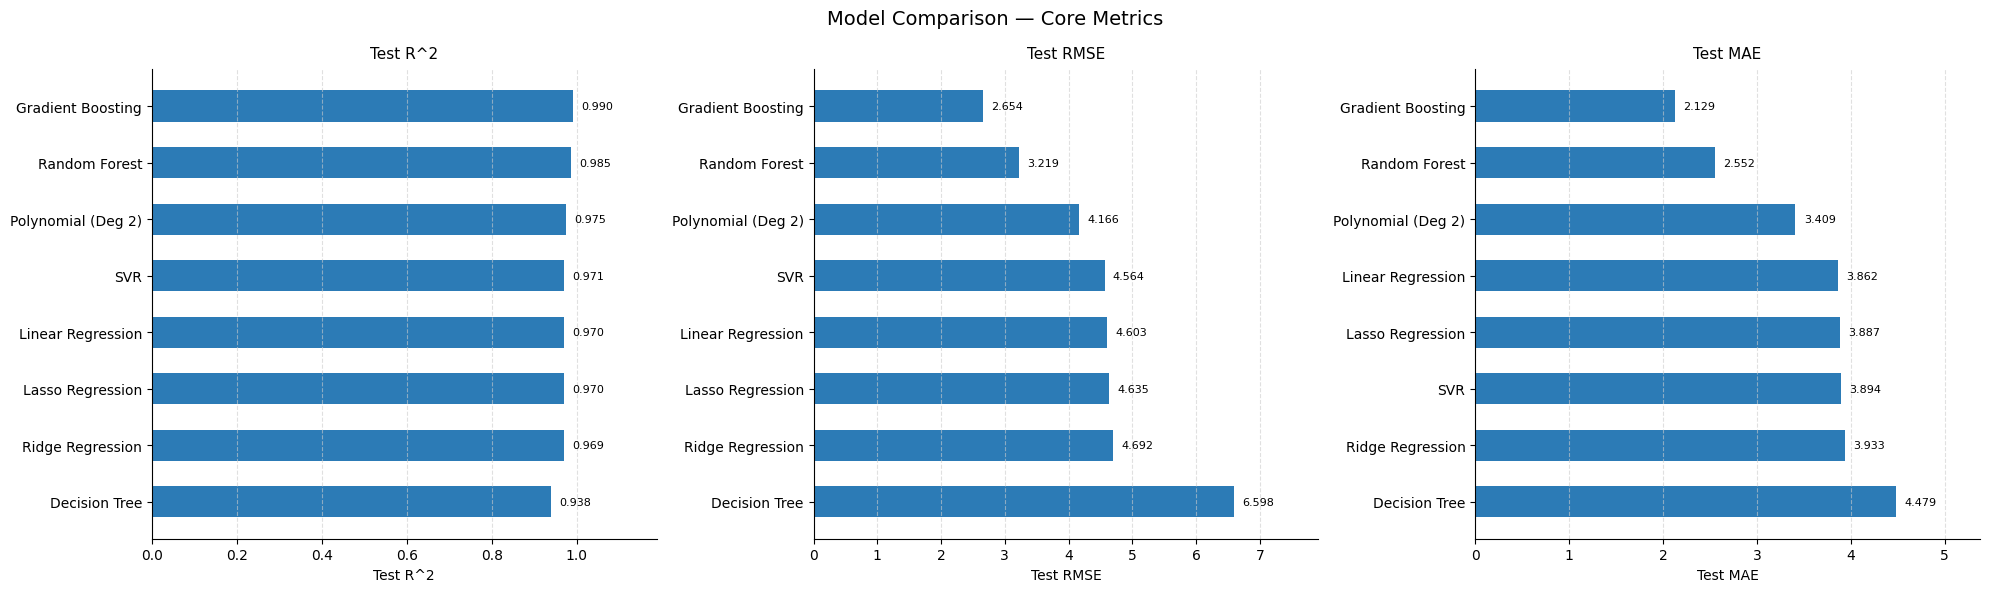

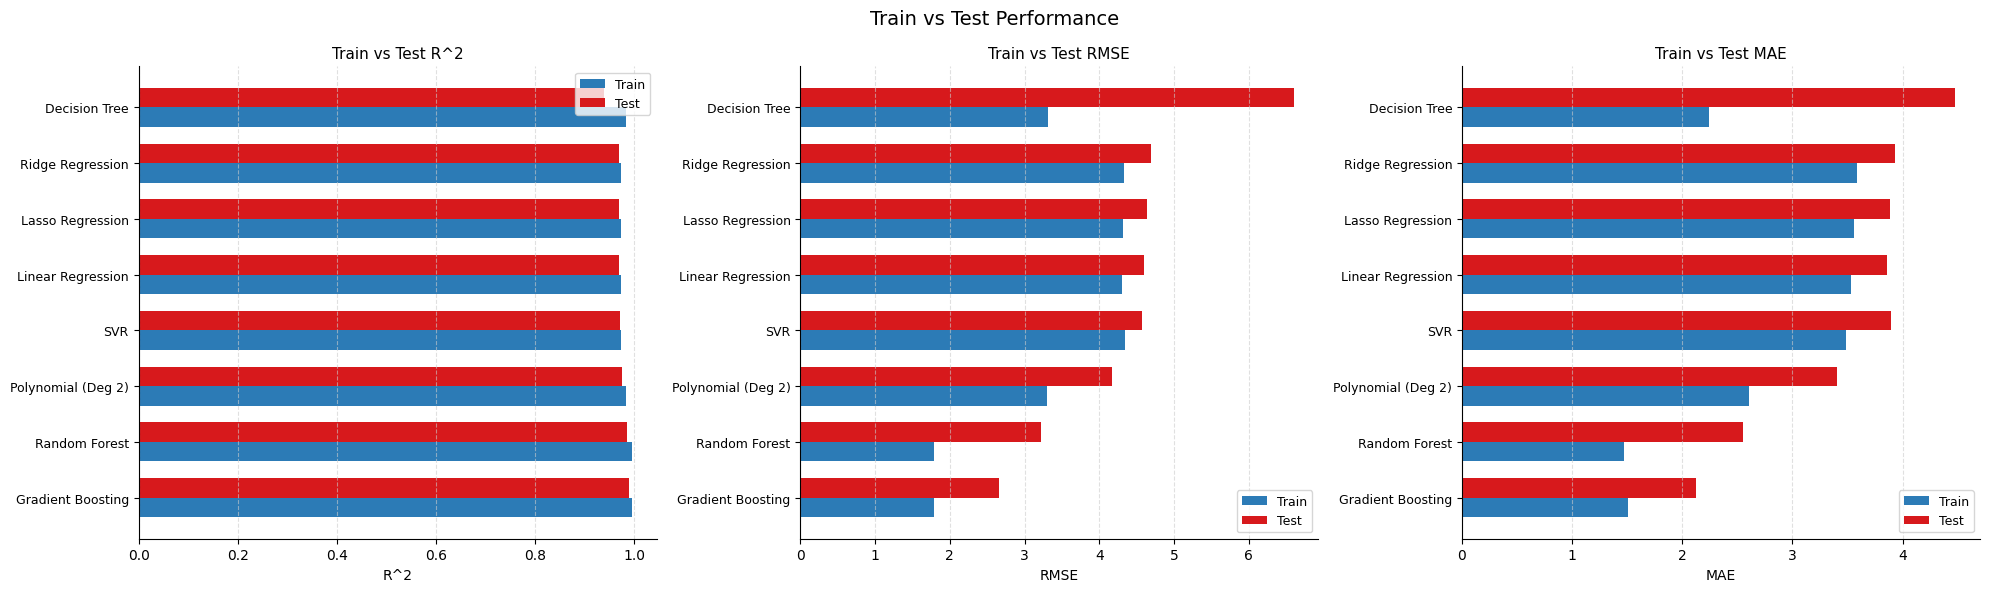

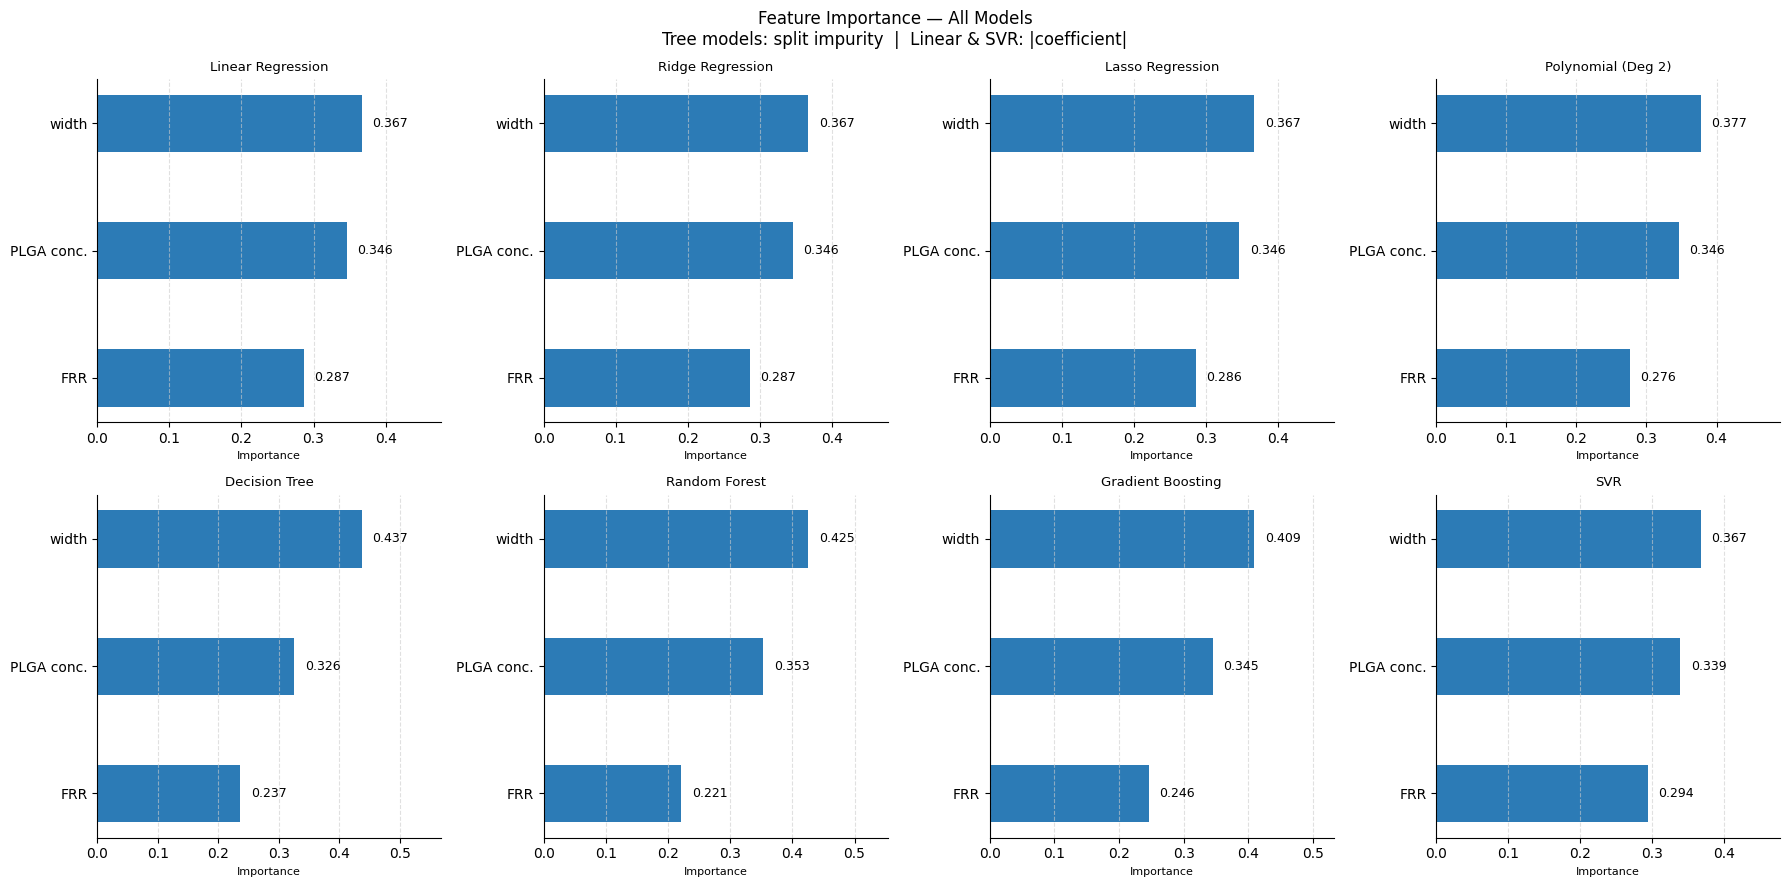


All figures saved.


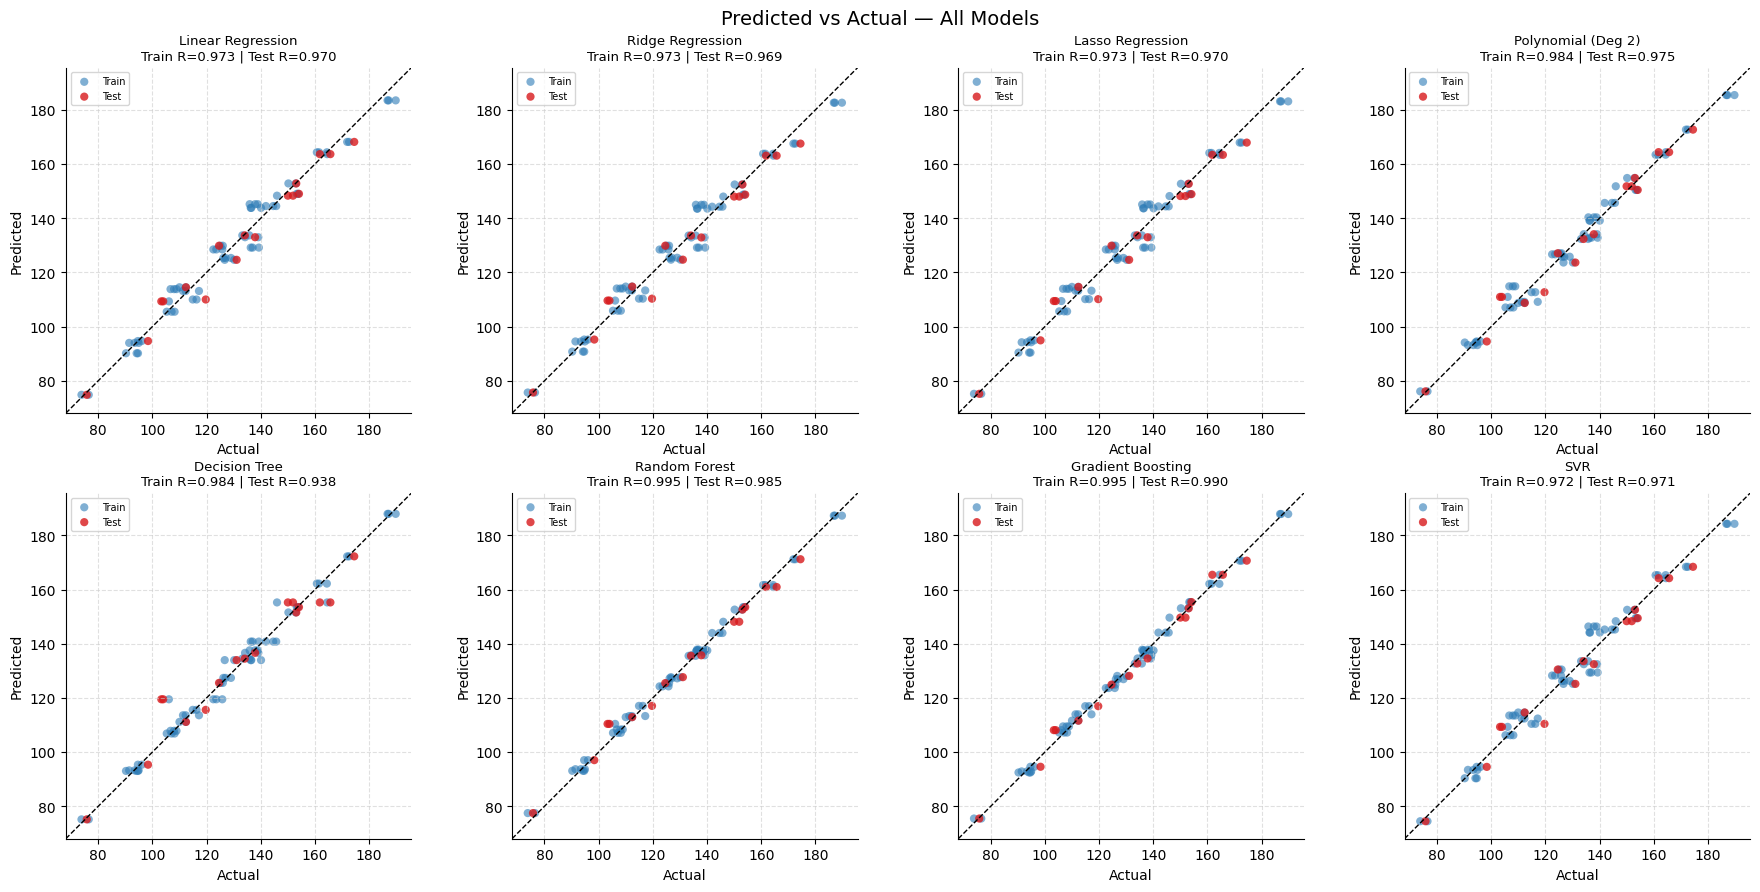

Figure 4 (Predicted vs Actual) saved.

5-Fold Cross-Validation Results (mean ± std across folds):
             Model  CV R (mean)  CV R (std)  CV RMSE (mean)  CV RMSE (std)  CV MAE (mean)  CV MAE (std)
 Gradient Boosting     0.984144    0.010002        2.890793       0.404668       2.417825      0.364862
     Random Forest     0.979055    0.006954        3.581938       0.724759       2.900572      0.534776
Polynomial (Deg 2)     0.968644    0.009515        4.322692       0.382506       3.356398      0.242486
  Ridge Regression     0.962334    0.018268        4.616762       0.311592       3.857730      0.190095
  Lasso Regression     0.962197    0.019173        4.598074       0.319338       3.836367      0.154166
 Linear Regression     0.962059    0.019921        4.586236       0.346022       3.826848      0.162888
               SVR     0.959947    0.022492        4.687142       0.461903       3.919530      0.271991
     Decision Tree     0.951150    0.033536        5.108964       1.40

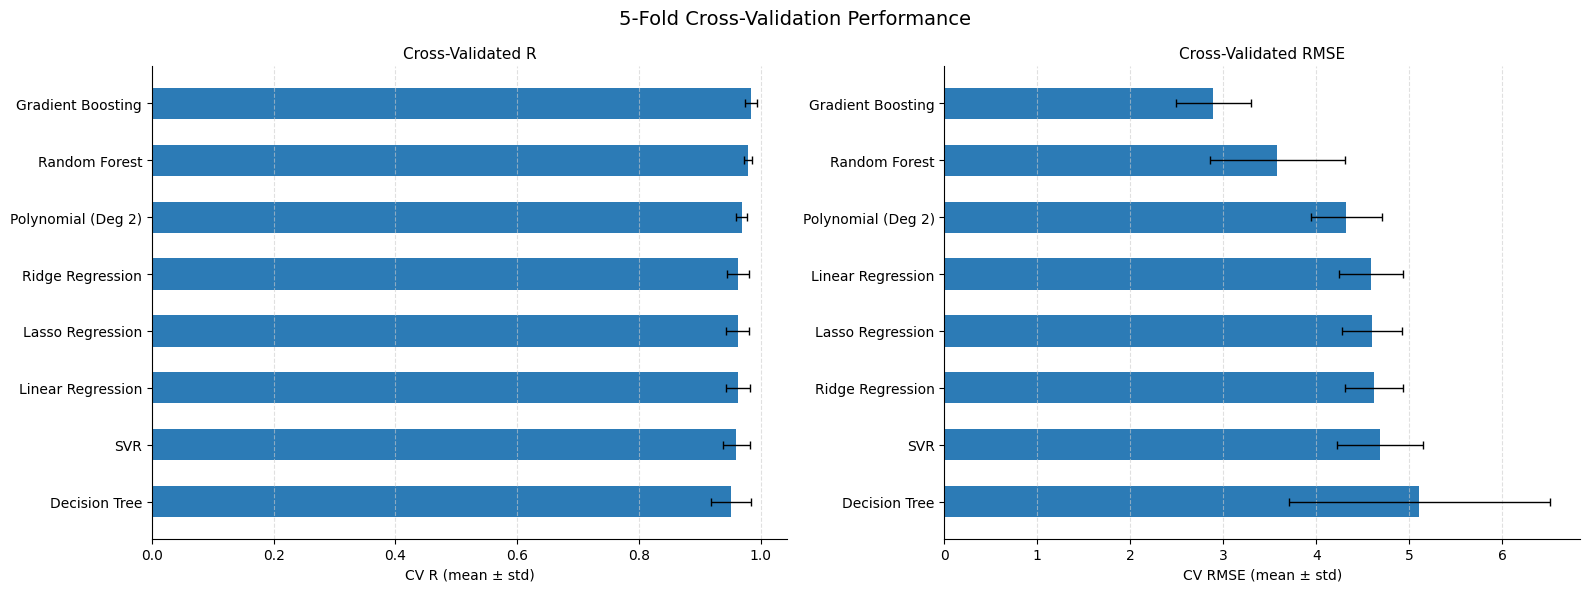

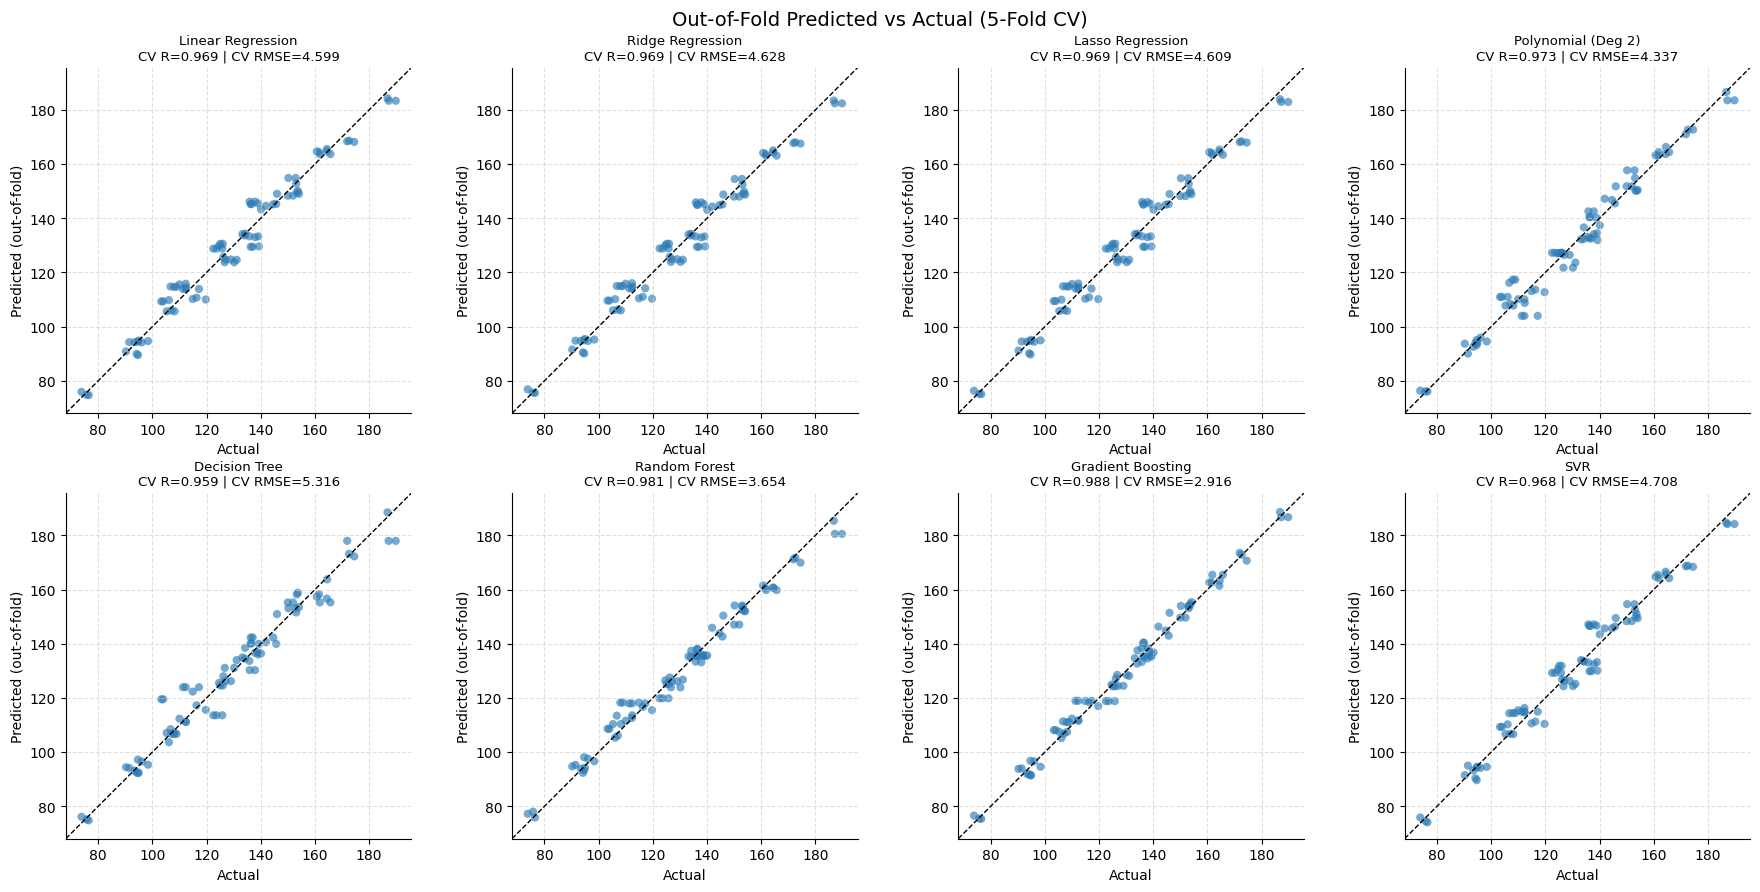


K-fold CV results and figures (5, 6) saved.
CSV table 'kfold_cv_results.csv' saved for use in Supporting Information.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# ── Styling ────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'axes.edgecolor':   'black',
    'axes.labelcolor':  'black',
    'xtick.color':      'black',
    'ytick.color':      'black',
    'text.color':       'black',
    'grid.color':       '#cccccc',
    'grid.linestyle':   '--',
    'grid.alpha':       0.6,
    'font.family':      'sans-serif',
    'axes.spines.top':  False,
    'axes.spines.right':False,
})

BAR_COLOR  = '#2c7bb6'   # single blue for all bars
TRAIN_COL  = '#2c7bb6'
TEST_COL   = '#d7191c'

# ── 1. Load data ────────────────────────────────────────────
df = pd.read_csv('Book4.xlsx - Sheet1.csv')
X = df[['FRR', 'PLGA conc.', 'width']]
y = df['size']
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ── 2. Models ────────────────────────────────────────────
models = {
    "Linear Regression":  make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression":   make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso Regression":   make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "Polynomial (Deg 2)": make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression()),
    "Decision Tree":      DecisionTreeRegressor(random_state=42, max_depth=5),
    "Random Forest":      RandomForestRegressor(random_state=42, n_estimators=100),
    "Gradient Boosting":  GradientBoostingRegressor(random_state=42, n_estimators=100),
    "SVR":                make_pipeline(StandardScaler(), SVR(kernel='linear', C=100, gamma=0.1)),
}

# ── 3. Fit & collect metrics ─────────────────────────────────
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    ytr = model.predict(X_train)
    yte = model.predict(X_test)
    results.append({
        "Model":      name,
        "Train R^2":   r2_score(y_train, ytr),
        "Test R^2":    r2_score(y_test,  yte),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, ytr)),
        "Test RMSE":  np.sqrt(mean_squared_error(y_test,  yte)),
        "Train MSE":  mean_squared_error(y_train, ytr), # Added Train MSE
        "Test MSE":   mean_squared_error(y_test,  yte), # Added Test MSE
        "Train MAE":  mean_absolute_error(y_train, ytr),
        "Test MAE":   mean_absolute_error(y_test,  yte),
    })

rdf = pd.DataFrame(results).sort_values("Test R^2", ascending=False)
print(rdf.to_string(index=False))

# ── helper ────────────────────────────────────────────
def hbar(ax, values, labels, xlabel, title):
    bars = ax.barh(labels, values, color=BAR_COLOR, edgecolor='none', height=0.55)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_xlim(0, max(values) * 1.2)
    ax.grid(axis='x')
    for bar, v in zip(bars, values):
        ax.text(bar.get_width() + max(values) * 0.02,
                bar.get_y() + bar.get_height() / 2,
                f"{v:.3f}", va='center', fontsize=8)

# ═══════════════════════════════════════════════════════════
# FIGURE 1 — Core metrics: R, RMSE, MAE
# ═══════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Model Comparison — Core Metrics", fontsize=14)

hbar(axes[0], rdf.sort_values("Test R^2",   ascending=True)["Test R^2"].values,
              rdf.sort_values("Test R^2",   ascending=True)["Model"].tolist(),
     "Test R^2",   "Test R^2")

hbar(axes[1], rdf.sort_values("Test RMSE", ascending=False)["Test RMSE"].values,
              rdf.sort_values("Test RMSE", ascending=False)["Model"].tolist(),
     "Test RMSE", "Test RMSE")

hbar(axes[2], rdf.sort_values("Test MAE",  ascending=False)["Test MAE"].values,
              rdf.sort_values("Test MAE",  ascending=False)["Model"].tolist(),
     "Test MAE",  "Test MAE")

plt.tight_layout()
plt.savefig('fig1_core_metrics.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ═══════════════════════════════════════════════════════════
# FIGURE 2 — Train vs Test R^2 and RMSE
# ═══════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Train vs Test Performance", fontsize=14)

x = np.arange(len(rdf)); w = 0.35
for ax, tc, vc, xl, title in [
    (axes[0], "Train R^2",   "Test R^2",   "R^2",   "Train vs Test R^2"),
    (axes[1], "Train RMSE", "Test RMSE", "RMSE", "Train vs Test RMSE"),
    (axes[2], "Train MAE",  "Test MAE",  "MAE",  "Train vs Test MAE"),

]:
    ax.barh(x - w/2, rdf[tc], w, label="Train", color=TRAIN_COL, edgecolor='none')
    ax.barh(x + w/2, rdf[vc], w, label="Test",  color=TEST_COL,  edgecolor='none')
    ax.set_yticks(x)
    ax.set_yticklabels(rdf["Model"], fontsize=9)
    ax.set_xlabel(xl)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(axis='x')

plt.tight_layout()
plt.savefig('fig2_train_vs_test.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ═══════════════════════════════════════════════════════════
# FIGURE 3 — Feature Importance (all 8 models)
# ═══════════════════════════════════════════════════════════
def get_importances(name, model, feature_names):
    if hasattr(model, 'feature_importances_'):
        return model.feature_importances_, feature_names

    if hasattr(model, 'named_steps'):
        steps    = list(model.named_steps.values())
        est      = steps[-1]
        has_poly = any(isinstance(s, PolynomialFeatures) for s in steps)

        if hasattr(est, 'coef_'):
            coefs = np.abs(est.coef_.flatten())

            if has_poly:
                poly   = next(s for s in steps if isinstance(s, PolynomialFeatures))
                powers = poly.powers_
                imp    = np.zeros(len(feature_names))
                for term_idx, power_row in enumerate(powers):
                    if term_idx >= len(coefs):
                        break
                    for feat_idx, p in enumerate(power_row):
                        if p > 0:
                            imp[feat_idx] += coefs[term_idx]
                return imp / (imp.sum() + 1e-12), feature_names

            return coefs / (coefs.sum() + 1e-12), feature_names

    return None, None


ncols = 4
nrows = int(np.ceil(len(models) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4.5))
axes = axes.flatten()
fig.suptitle(
    "Feature Importance — All Models\n"
    "Tree models: split impurity  |  Linear & SVR: |coefficient|",
    fontsize=12
)

for i, (name, model) in enumerate(models.items()):
    imp, labs = get_importances(name, model, feature_names)
    ax = axes[i]

    if imp is None:
        ax.set_visible(False) # Make the axis invisible
        continue

    order  = np.argsort(imp)
    f_labs = [labs[j] for j in order]
    f_imp  = imp[order]

    bars = ax.barh(f_labs, f_imp, color=BAR_COLOR, edgecolor='none', height=0.45)

    for bar, v in zip(bars, f_imp):
        ax.text(bar.get_width() + f_imp.max() * 0.04,
                bar.get_y() + bar.get_height() / 2,
                f"{v:.3f}", va='center', fontsize=9)

    ax.set_xlim(0, f_imp.max() * 1.3)
    ax.set_title(name, fontsize=9.5, pad=6)
    ax.set_xlabel("Importance", fontsize=8)
    ax.grid(axis='x')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('fig3_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

print("\nAll figures saved.")
# ═══════════════════════════════════════════════════════════
# FIGURE 4 — Predicted vs Actual (all models)
# ═══════════════════════════════════════════════════════════
ncols = 4
nrows = int(np.ceil(len(models) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4.5))
axes = axes.flatten()
fig.suptitle("Predicted vs Actual — All Models", fontsize=14)

# Shared axis limits so every panel is comparable
all_vals = np.concatenate([y_train.values, y_test.values])
lo, hi = all_vals.min(), all_vals.max()
pad = (hi - lo) * 0.05
lo, hi = lo - pad, hi + pad

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]
    ytr_pred = model.predict(X_train)
    yte_pred = model.predict(X_test)

    ax.scatter(y_train, ytr_pred, color=TRAIN_COL, alpha=0.6, s=35,
               edgecolor='none', label='Train')
    ax.scatter(y_test, yte_pred, color=TEST_COL, alpha=0.8, s=35,
               edgecolor='none', label='Test')

    # Ideal y = x reference line
    ax.plot([lo, hi], [lo, hi], color='black', linestyle='--', linewidth=1)

    train_r2 = r2_score(y_train, ytr_pred)
    test_r2  = r2_score(y_test,  yte_pred)

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{name}\nTrain R={train_r2:.3f} | Test R={test_r2:.3f}",
                 fontsize=9.5, pad=6)
    ax.grid(True)
    ax.legend(fontsize=7, loc='upper left')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('fig4_pred_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

print("Figure 4 (Predicted vs Actual) saved.")

# ═══════════════════════════════════════════════════════════
# K-FOLD CROSS-VALIDATION (add after the train/test split section,
# before or after the single train/test fit — works either way since
# this re-fits each model fresh within each fold)
# ═══════════════════════════════════════════════════════════
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict

N_SPLITS = 5  # change to 10 if you have enough samples; 5 is standard for small N

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

cv_results = []
cv_predictions = {}  # store out-of-fold predictions for plotting later

for name, model in models.items():
    # R across folds
    r2_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

    # RMSE across folds (sklearn returns neg MSE, so flip sign and sqrt)
    neg_mse_scores = cross_val_score(model, X, y, cv=kf,
                                      scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-neg_mse_scores)

    # MAE across folds
    neg_mae_scores = cross_val_score(model, X, y, cv=kf,
                                      scoring='neg_mean_absolute_error')
    mae_scores = -neg_mae_scores

    # Out-of-fold predictions (each sample predicted exactly once, by the
    # fold where it was held out) — useful for an honest pred-vs-actual plot
    y_pred_cv = cross_val_predict(model, X, y, cv=kf)
    cv_predictions[name] = y_pred_cv

    cv_results.append({
        "Model":        name,
        "CV R (mean)":  r2_scores.mean(),
        "CV R (std)":   r2_scores.std(),
        "CV RMSE (mean)": rmse_scores.mean(),
        "CV RMSE (std)":  rmse_scores.std(),
        "CV MAE (mean)":  mae_scores.mean(),
        "CV MAE (std)":   mae_scores.std(),
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV R (mean)", ascending=False)
print(f"\n{N_SPLITS}-Fold Cross-Validation Results (mean ± std across folds):")
print(cv_df.to_string(index=False))

# Save to CSV for easy inclusion in SI tables
cv_df.to_csv('kfold_cv_results.csv', index=False)

# ═══════════════════════════════════════════════════════════
# FIGURE 5 — K-Fold CV: R and RMSE with error bars (std across folds)
# ═══════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f"{N_SPLITS}-Fold Cross-Validation Performance", fontsize=14)

cv_sorted_r2 = cv_df.sort_values("CV R (mean)", ascending=True)
axes[0].barh(cv_sorted_r2["Model"], cv_sorted_r2["CV R (mean)"],
             xerr=cv_sorted_r2["CV R (std)"],
             color=BAR_COLOR, edgecolor='none', height=0.55,
             error_kw={'ecolor': 'black', 'capsize': 3, 'elinewidth': 1})
axes[0].set_xlabel("CV R (mean ± std)")
axes[0].set_title("Cross-Validated R", fontsize=11)
axes[0].grid(axis='x')

cv_sorted_rmse = cv_df.sort_values("CV RMSE (mean)", ascending=False)
axes[1].barh(cv_sorted_rmse["Model"], cv_sorted_rmse["CV RMSE (mean)"],
             xerr=cv_sorted_rmse["CV RMSE (std)"],
             color=BAR_COLOR, edgecolor='none', height=0.55,
             error_kw={'ecolor': 'black', 'capsize': 3, 'elinewidth': 1})
axes[1].set_xlabel("CV RMSE (mean ± std)")
axes[1].set_title("Cross-Validated RMSE", fontsize=11)
axes[1].grid(axis='x')

plt.tight_layout()
plt.savefig('fig5_kfold_cv.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ═══════════════════════════════════════════════════════════
# FIGURE 6 — Out-of-fold Predicted vs Actual (all models)
# Each point predicted only when it was in the held-out fold —
# this is the most honest "predicted vs actual" plot you can show,
# since no point is ever predicted by a model trained on itself.
# ═══════════════════════════════════════════════════════════
ncols = 4
nrows = int(np.ceil(len(models) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4.5))
axes = axes.flatten()
fig.suptitle(f"Out-of-Fold Predicted vs Actual ({N_SPLITS}-Fold CV)", fontsize=14)

lo, hi = y.min(), y.max()
pad = (hi - lo) * 0.05
lo, hi = lo - pad, hi + pad

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]
    y_pred_cv = cv_predictions[name]

    ax.scatter(y, y_pred_cv, color=BAR_COLOR, alpha=0.65, s=35, edgecolor='none')
    ax.plot([lo, hi], [lo, hi], color='black', linestyle='--', linewidth=1)

    cv_r2 = r2_score(y, y_pred_cv)
    cv_rmse = np.sqrt(mean_squared_error(y, y_pred_cv))

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted (out-of-fold)")
    ax.set_title(f"{name}\nCV R={cv_r2:.3f} | CV RMSE={cv_rmse:.3f}",
                 fontsize=9.5, pad=6)
    ax.grid(True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('fig6_kfold_pred_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

print("\nK-fold CV results and figures (5, 6) saved.")
print("CSV table 'kfold_cv_results.csv' saved for use in Supporting Information.")

### Data for Plots

Below, you'll find the data used to generate the plots, which you can easily copy or save to a CSV file for use in Excel or other tools.


#### Figure 1 & 2 Data: Core Metrics and Train vs Test Performance

This table contains the R², RMSE, and MAE for both training and test sets for all models. This data is used in both Figure 1 (Core Metrics) and Figure 2 (Train vs Test Performance).


In [2]:
print('--- Data for Figure 1 & 2 (Core Metrics and Train vs Test) ---')
display(rdf)
rdf.to_csv('core_metrics_data.csv', index=False)
print('Data saved to core_metrics_data.csv')


--- Data for Figure 1 & 2 (Core Metrics and Train vs Test) ---


,Model,Train R^2,Test R^2,Train RMSE,Test RMSE,Train MSE,Test MSE,Train MAE,Test MAE
6,Gradient Boosting,0.995321,0.990028,1.789274,2.653856,3.201502,7.042953,1.506924,2.129182
5,Random Forest,0.995315,0.985328,1.790429,3.219138,3.205636,10.362848,1.469946,2.551992
3,Polynomial (Deg 2),0.984073,0.975425,3.301126,4.166218,10.897431,17.357376,2.604057,3.409403
7,SVR,0.972391,0.970502,4.346281,4.564450,18.890161,20.834207,3.489998,3.894442
0,Linear Regression,0.972892,0.969998,4.306630,4.603287,18.547064,21.190252,3.534161,3.861970
2,Lasso Regression,0.972847,0.969585,4.310175,4.634909,18.577608,21.482386,3.555245,3.886958
1,Ridge Regression,0.972654,0.968832,4.325463,4.691925,18.709629,22.014156,3.583028,3.933436
4,Decision Tree,0.983934,0.938357,3.315410,6.598366,10.991945,43.538431,2.241927,4.479118


Data saved to core_metrics_data.csv


#### Figure 3 Data: Feature Importance

This table contains the feature importances for each model. Note that some models (like Linear, Ridge, Lasso, and SVR) have coefficients rather than direct feature importances, and their absolute values are used as a proxy for importance here.


In [3]:
print('--- Data for Figure 3 (Feature Importance) ---')

feature_importance_data = []
for name, model in models.items():
    imp, labs = get_importances(name, model, feature_names)
    if imp is not None:
        model_importance = {'Model': name}
        for lab, importance_val in zip(labs, imp):
            model_importance[lab] = importance_val
        feature_importance_data.append(model_importance)

feature_importance_df = pd.DataFrame(feature_importance_data)
display(feature_importance_df)
feature_importance_df.to_csv('feature_importance_data.csv', index=False)
print('Data saved to feature_importance_data.csv')


--- Data for Figure 3 (Feature Importance) ---


,Model,FRR,PLGA conc.,width
0,Linear Regression,0.286586,0.346288,0.367127
1,Ridge Regression,0.286660,0.345949,0.367391
2,Lasso Regression,0.286291,0.346213,0.367497
3,Polynomial (Deg 2),0.276437,0.346259,0.377304
4,Decision Tree,0.236604,0.325965,0.437431
5,Random Forest,0.221442,0.353153,0.425404
6,Gradient Boosting,0.245829,0.344847,0.409324
7,SVR,0.293640,0.339021,0.367339


Data saved to feature_importance_data.csv


In [4]:
# y = m1x1+m2x2+m2x3+b

# based on the given size parameter i want to get the values for the other three variables such as FRR, conc, and width.
# Use the linear or polynomial regression algorithm.




### Inverse Prediction: Estimating FRR, PLGA Conc., and Width from Size

Since the original problem predicted `size` from 'FRR', 'PLGA conc.', and 'width', we now need to solve the inverse problem: predicting 'FRR', 'PLGA conc.', and 'width' given a `size`. This typically involves training separate models for each of these output variables, using `size` as the input feature.

Here, we will train three individual `LinearRegression` models:
1.  `FRR = f(size)`
2.  `PLGA conc. = g(size)`
3.  `width = h(size)`

This approach directly addresses your request to use a linear regression algorithm to find the values of the other three variables based on a given `size`.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
import copy # Import copy module

# Prepare the data for inverse prediction
X_inverse = df[['size']]
y_frr = df['FRR']
y_plga_conc = df['PLGA conc.']
y_width = df['width']

# Dictionary to store the trained inverse models
inverse_models = {}

# Define the inverse model types requested by the user
# inverse_model_types = {
#     "Linear Regression": make_pipeline(LinearRegression()),
#     "Polynomial (Deg 2)": make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
#     "Gradient Boosting": GradientBoostingRegressor(random_state=42, n_estimators=100),
#     "Random Forest": RandomForestRegressor(random_state=42, n_estimators=100)
# }

inverse_model_types = {
    "Gradient Boosting": GradientBoostingRegressor(random_state=42, n_estimators=100),
    "SVR": make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, gamma=0.1)),
    "Polynomial (Deg 2)": make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
    "Linear Regression": make_pipeline(LinearRegression())
}

# Train models for FRR
print("Training models for FRR:")
X_train_frr, X_test_frr, y_train_frr, y_test_frr = train_test_split(X_inverse, y_frr, test_size=0.2, random_state=42)
for name, model_template in inverse_model_types.items(): # Use model_template to deepcopy
    model_pipeline = copy.deepcopy(model_template) # Create a deep copy for independent training
    model_pipeline.fit(X_train_frr, y_train_frr)
    inverse_models[f'FRR_{name}'] = model_pipeline
    r2 = r2_score(y_test_frr, model_pipeline.predict(X_test_frr))
    print(f"  {name} (FRR) Test R²: {r2:.4f}")

# Train models for PLGA conc.
print("\nTraining models for PLGA conc.:")
X_train_plga, X_test_plga, y_train_plga, y_test_plga = train_test_split(X_inverse, y_plga_conc, test_size=0.2, random_state=42)
for name, model_template in inverse_model_types.items(): # Use model_template to deepcopy
    model_pipeline = copy.deepcopy(model_template) # Create a deep copy for independent training
    model_pipeline.fit(X_train_plga, y_train_plga)
    inverse_models[f'PLGA conc._{name}'] = model_pipeline
    r2 = r2_score(y_test_plga, model_pipeline.predict(X_test_plga))
    print(f"  {name} (PLGA conc.) Test R²: {r2:.4f}")

# Train models for width
print("\nTraining models for width:")
X_train_width, X_test_width, y_train_width, y_test_width = train_test_split(X_inverse, y_width, test_size=0.2, random_state=42)
for name, model_template in inverse_model_types.items(): # Use model_template to deepcopy
    model_pipeline = copy.deepcopy(model_template) # Create a deep copy for independent training
    model_pipeline.fit(X_train_width, y_train_width)
    inverse_models[f'width_{name}'] = model_pipeline
    r2 = r2_score(y_test_width, model_pipeline.predict(X_test_width))
    print(f"  {name} (width) Test R²: {r2:.4f}")

print("\nAll models trained successfully.")

Training models for FRR:
  Gradient Boosting (FRR) Test R²: 0.1043
  SVR (FRR) Test R²: -0.0625
  Polynomial (Deg 2) (FRR) Test R²: 0.0036
  Linear Regression (FRR) Test R²: 0.0227

Training models for PLGA conc.:
  Gradient Boosting (PLGA conc.) Test R²: 0.0381
  SVR (PLGA conc.) Test R²: 0.5535
  Polynomial (Deg 2) (PLGA conc.) Test R²: 0.5570
  Linear Regression (PLGA conc.) Test R²: 0.5565

Training models for width:
  Gradient Boosting (width) Test R²: 0.3515
  SVR (width) Test R²: 0.0269
  Polynomial (Deg 2) (width) Test R²: 0.2023
  Linear Regression (width) Test R²: 0.2032

All models trained successfully.


### Make Predictions with the Inverse Models

Now you can use the trained models to predict 'FRR', 'PLGA conc.', and 'width' for a given `size` value. Enter your desired `size` below to get predictions.


In [11]:
#@title Enter a size value to predict FRR, PLGA conc., and Width
predicted_size = 120 # @param {type:"number"}

# Convert the single input to a DataFrame as expected by the models
input_df = pd.DataFrame({'size': [predicted_size]})

# Define allowed absolute width values for rounding
allowed_widths = np.array([100, 200, 300])

# Define allowed PLGA conc. values for rounding
allowed_plga_conc_values = np.array([2.5, 5.0, 7.5])

print(f"For a given size of {predicted_size:.2f}:\n")

# Iterate through each model type and make predictions
# inverse_model_names = [
#     "Linear Regression",
#     "Polynomial (Deg 2)",
#     "Gradient Boosting",
#     "Random Forest"
# ]

inverse_model_names = [
    "Gradient Boosting",
    "SVR",
    "Polynomial (Deg 2)",
    "Linear Regression"
]

for model_name in inverse_model_names:
    print(f"--- Predictions using {model_name} ---")

    # Predict FRR
    predicted_frr = inverse_models[f'FRR_{model_name}'].predict(input_df)[0]

    # Predict PLGA conc.
    predicted_plga_conc_linear = inverse_models[f'PLGA conc._{model_name}'].predict(input_df)[0]
    # Find the closest allowed PLGA conc. value
    predicted_plga_conc_rounded = allowed_plga_conc_values[np.argmin(np.abs(allowed_plga_conc_values - predicted_plga_conc_linear))]

    # Predict width using the linear model (before rounding)
    predicted_width_linear = inverse_models[f'width_{model_name}'].predict(input_df)[0]

    # Find the closest allowed width value
    predicted_width_rounded = allowed_widths[np.argmin(np.abs(allowed_widths - predicted_width_linear))]

    print(f"  Predicted FRR: {predicted_frr:.4f}")
    print(f"  Predicted PLGA conc.: {predicted_plga_conc_rounded:.1f}")
    print(f"  Predicted Width (rounded to closest allowed): {predicted_width_rounded:.0f}")
    print("\n")

For a given size of 120.00:

--- Predictions using Gradient Boosting ---
  Predicted FRR: 0.1001
  Predicted PLGA conc.: 7.5
  Predicted Width (rounded to closest allowed): 100


--- Predictions using SVR ---
  Predicted FRR: 0.1000
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200


--- Predictions using Polynomial (Deg 2) ---
  Predicted FRR: 0.0978
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200


--- Predictions using Linear Regression ---
  Predicted FRR: 0.0955
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200




In [7]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.svm import SVR
import copy # Import copy module

# Prepare the data for inverse prediction
X_inverse = df[['size']]
y_frr = df['FRR']
y_plga_conc = df['PLGA conc.']
y_width = df['width']

# Dictionary to store the trained inverse models
inverse_models = {}

# All 8 inverse model types (matches the forward-model set)
inverse_model_types = {
    "Linear Regression":  make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression":   make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso Regression":   make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "Polynomial (Deg 2)": make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression()),
    "Decision Tree":      DecisionTreeRegressor(random_state=42, max_depth=5),
    "Random Forest":      RandomForestRegressor(random_state=42, n_estimators=100),
    "Gradient Boosting":  GradientBoostingRegressor(random_state=42, n_estimators=100),
    "SVR":                make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, gamma=0.1)),
}

# Train models for FRR
print("Training models for FRR:")
X_train_frr, X_test_frr, y_train_frr, y_test_frr = train_test_split(X_inverse, y_frr, test_size=0.2, random_state=42)
for name, model_template in inverse_model_types.items(): # Use model_template to deepcopy
    model_pipeline = copy.deepcopy(model_template) # Create a deep copy for independent training
    model_pipeline.fit(X_train_frr, y_train_frr)
    inverse_models[f'FRR_{name}'] = model_pipeline
    r2 = r2_score(y_test_frr, model_pipeline.predict(X_test_frr))
    print(f"  {name} (FRR) Test R²: {r2:.4f}")

# Train models for PLGA conc.
print("\nTraining models for PLGA conc.:")
X_train_plga, X_test_plga, y_train_plga, y_test_plga = train_test_split(X_inverse, y_plga_conc, test_size=0.2, random_state=42)
for name, model_template in inverse_model_types.items(): # Use model_template to deepcopy
    model_pipeline = copy.deepcopy(model_template) # Create a deep copy for independent training
    model_pipeline.fit(X_train_plga, y_train_plga)
    inverse_models[f'PLGA conc._{name}'] = model_pipeline
    r2 = r2_score(y_test_plga, model_pipeline.predict(X_test_plga))
    print(f"  {name} (PLGA conc.) Test R²: {r2:.4f}")

# Train models for width
print("\nTraining models for width:")
X_train_width, X_test_width, y_train_width, y_test_width = train_test_split(X_inverse, y_width, test_size=0.2, random_state=42)
for name, model_template in inverse_model_types.items(): # Use model_template to deepcopy
    model_pipeline = copy.deepcopy(model_template) # Create a deep copy for independent training
    model_pipeline.fit(X_train_width, y_train_width)
    inverse_models[f'width_{name}'] = model_pipeline
    r2 = r2_score(y_test_width, model_pipeline.predict(X_test_width))
    print(f"  {name} (width) Test R²: {r2:.4f}")

print("\nAll models trained successfully.")

Training models for FRR:
  Linear Regression (FRR) Test R²: 0.0227
  Ridge Regression (FRR) Test R²: 0.0263
  Lasso Regression (FRR) Test R²: -0.1001
  Polynomial (Deg 2) (FRR) Test R²: 0.0036
  Decision Tree (FRR) Test R²: -0.0233
  Random Forest (FRR) Test R²: 0.3122
  Gradient Boosting (FRR) Test R²: 0.1043
  SVR (FRR) Test R²: -0.0625

Training models for PLGA conc.:
  Linear Regression (PLGA conc.) Test R²: 0.5565
  Ridge Regression (PLGA conc.) Test R²: 0.5519
  Lasso Regression (PLGA conc.) Test R²: 0.5275
  Polynomial (Deg 2) (PLGA conc.) Test R²: 0.5570
  Decision Tree (PLGA conc.) Test R²: 0.0319
  Random Forest (PLGA conc.) Test R²: 0.1141
  Gradient Boosting (PLGA conc.) Test R²: 0.0381
  SVR (PLGA conc.) Test R²: 0.5535

Training models for width:
  Linear Regression (width) Test R²: 0.2032
  Ridge Regression (width) Test R²: 0.2075
  Lasso Regression (width) Test R²: 0.2038
  Polynomial (Deg 2) (width) Test R²: 0.2023
  Decision Tree (width) Test R²: 0.1310
  Random Fores

In [12]:
#@title Enter a size value to predict FRR, PLGA conc., and Width
predicted_size = 120 # @param {type:"number"}

# Convert the single input to a DataFrame as expected by the models
input_df = pd.DataFrame({'size': [predicted_size]})

# Define allowed absolute width values for rounding
allowed_widths = np.array([100, 200, 300])

# Define allowed PLGA conc. values for rounding
allowed_plga_conc_values = np.array([2.5, 5.0, 7.5])

print(f"For a given size of {predicted_size:.2f}:\n")

# All 8 inverse model types — must match the keys built in inverse_models
inverse_model_names = [
    "Linear Regression",
    "Ridge Regression",
    "Lasso Regression",
    "Polynomial (Deg 2)",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "SVR",
]

for model_name in inverse_model_names:
    print(f"--- Predictions using {model_name} ---")

    # Predict FRR
    predicted_frr = inverse_models[f'FRR_{model_name}'].predict(input_df)[0]

    # Predict PLGA conc.
    predicted_plga_conc_linear = inverse_models[f'PLGA conc._{model_name}'].predict(input_df)[0]
    # Find the closest allowed PLGA conc. value
    predicted_plga_conc_rounded = allowed_plga_conc_values[np.argmin(np.abs(allowed_plga_conc_values - predicted_plga_conc_linear))]

    # Predict width using the linear model (before rounding)
    predicted_width_linear = inverse_models[f'width_{model_name}'].predict(input_df)[0]

    # Find the closest allowed width value
    predicted_width_rounded = allowed_widths[np.argmin(np.abs(allowed_widths - predicted_width_linear))]

    print(f"  Predicted FRR: {predicted_frr:.4f}")
    print(f"  Predicted PLGA conc.: {predicted_plga_conc_rounded:.1f}")
    print(f"  Predicted Width (rounded to closest allowed): {predicted_width_rounded:.0f}")
    print("\n")

For a given size of 120.00:

--- Predictions using Linear Regression ---
  Predicted FRR: 0.0955
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200


--- Predictions using Ridge Regression ---
  Predicted FRR: 0.0956
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200


--- Predictions using Lasso Regression ---
  Predicted FRR: 0.1023
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200


--- Predictions using Polynomial (Deg 2) ---
  Predicted FRR: 0.0978
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 200


--- Predictions using Decision Tree ---
  Predicted FRR: 0.1250
  Predicted PLGA conc.: 5.0
  Predicted Width (rounded to closest allowed): 100


--- Predictions using Random Forest ---
  Predicted FRR: 0.0900
  Predicted PLGA conc.: 7.5
  Predicted Width (rounded to closest allowed): 100


--- Predictions using Gradient Boosting ---
  Predicted FRR: 0.1001
  Predicted 

In [9]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful